In [1]:
from ech_discovery.notebook import *

In [2]:
df = (
    pl.read_parquet(list(config.INTERIM_DATA_DIR.glob("*/*/stats_*")))
    .filter(RANGES["main"].expr() | RANGES["followup"].expr())
    .filter(pl.col(C.kind) == "accepted")
    .filter(
        pl.col(C.measurement) == pl.col(C.measurement).max().over(C.location, C.role)
    )
    .sort(C.location, C.role)
).filter(
    pl.col(C.location) == "tud",
)

/mnt/data01/artifacts-active-ech/06-ech-analysis/reports/figures/public-name-stats/bar_slds_per_ech_public_name_tud.png


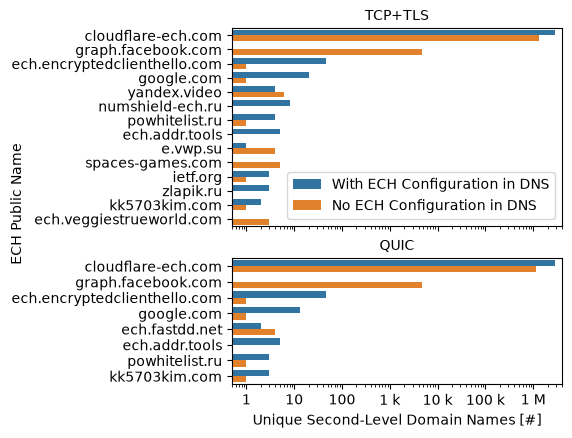

In [3]:
# combine ECH and non ECH
data = df.filter(
    ((pl.col(C.target_sld) >= 3).any().over(C.ech_public_name, C.location)),
)


def plot_one(data, location, **kws):

    lines = data.filter(pl.col(C.role) == "ech").select(pl.len()).item()
    lines_quic = data.filter(pl.col(C.role) == "ech-quic").select(pl.len()).item()
    fig, axs = vh.fig_ax(
        (6, lines * 0.21),
        sharex=True,
        nrows=2,
        height_ratios=[lines, lines_quic],
    )
    for ax, protocol in zip([axs[0], axs[1]], ["ech", "ech-quic"]):
        p_data = data.filter(pl.col(C.location) == location).filter(
            pl.col(C.role) == protocol
        )

        plot.plot_public_names_vs_slds(p_data, fig, ax, ylabel=None, xlabel=None)
        if protocol == "ech-quic":
            ax.legend().remove()
        ax.set(xlim=(0.5, 4_000_000))

        ax.set(**kws)

        ax.xaxis.set_major_formatter(ticker.EngFormatter())

    axs[1].set(xlabel=Strings.domain_names)
    for ax, title in zip(axs.flatten(), [role_map["ech"], role_map["ech-quic"]]):
        ax.set_title(
            title,
            fontsize=10,
        )

    fig.text(
        -0.02, 0.5, Strings.ech_public_name, va="center", rotation="vertical", fontsize=10
    )
    plt.subplots_adjust(left=0.35)
    fig.subplots_adjust(
        hspace=0.2,
    )
    vh.save_plot(
        fig,
        f"bar_slds_per_ech_public_name_{location}",
        directory=config.FIGURES_DIR / "public-name-stats",
    )
    plt.show()


for location in df.unique(C.location).get_column(C.location).to_list():

    plot_one(
        data,
        location,
    )


In [4]:
tdata = (
    data.sort(C.role, C.target_sld, descending=[False, True])
    .drop(C.measurement)
    .pivot(
        index=[C.ech_public_name, C.role], on=Strings.ech_in_dns, values=C.target_sld
    )
)


def get_table(tdata):

    return (
        GT(tdata)
        # .tab_header(title="ECH Deployment by SLD")
        .cols_label(
            **{
                C.ech_public_name: Strings.public_name_short,
                C.true: Strings.yes,
                C.false: Strings.no,
            }
        )
        .tab_spanner(
            label=Strings.ech_in_https,
            columns=[C.true, C.false],
        )
        .fmt_number(
            columns=[C.true, C.false],
            compact=True,
            decimals=1,
            drop_trailing_zeros=True,
        )
        .sub_missing(columns=[C.true, C.false], missing_text="-")
    )


get_table(tdata.filter(pl.col(C.role) == "ech").drop(C.role))

GT(_tbl_data=shape: (14, 3)
┌──────────────────────────────┬───────────┬───────────┐
│ ech_public_name              ┆ true      ┆ false     │
│ ---                          ┆ ---       ┆ ---       │
│ str                          ┆ u32       ┆ u32       │
╞══════════════════════════════╪═══════════╪═══════════╡
│ cloudflare-ech.com           ┆ 2,897,382 ┆ 1,340,256 │
│ graph.facebook.com           ┆ null      ┆ 4,658     │
│ ech.encryptedclienthello.com ┆ 46        ┆ 1         │
│ …                            ┆ …         ┆ …         │
│ zlapik.ru                    ┆ 3         ┆ null      │
│ kk5703kim.com                ┆ 2         ┆ 1         │
└──────────────────────────────┴───────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x70bce2fdd2b0>, _boxhead=Boxhead([ColInfo(var='ech_public_name', type=<ColInfoTypeEnum.default: 1>, column_label='Public Name', column_align='left', column_width=None), ColInfo(var='true', type=<ColInfoTypeEnum.default: 1>, column_label='Yes', column_align='right', column_width=None), ColInfo(var='false', type=<ColInfoTypeEnum.default: 1>, column_label='No', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x70bce2fdcd70>, _spanners=Spanners([SpannerInfo(spanner_id=<Strings.ech_in_https: 'ECH in HTTPS RRs'>, spanner_level=0, spanner_label='ECH in HTTPS RRs', spanner_units=None, spanner_pattern=None, vars=['true', 'false'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x70bce2fdd6a0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x70bce2fd9590>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x70bce2fdd7f0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x70bce2fdda90>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x70bce2fd9310>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', 

In [5]:
get_table(tdata.filter(pl.col(C.role) == "ech-quic").drop(C.role))

GT(_tbl_data=shape: (8, 3)
┌──────────────────────────────┬───────────┬───────────┐
│ ech_public_name              ┆ true      ┆ false     │
│ ---                          ┆ ---       ┆ ---       │
│ str                          ┆ u32       ┆ u32       │
╞══════════════════════════════╪═══════════╪═══════════╡
│ cloudflare-ech.com           ┆ 2,820,487 ┆ 1,144,349 │
│ graph.facebook.com           ┆ null      ┆ 4,651     │
│ ech.encryptedclienthello.com ┆ 46        ┆ 1         │
│ …                            ┆ …         ┆ …         │
│ powhitelist.ru               ┆ 3         ┆ 1         │
│ kk5703kim.com                ┆ 3         ┆ 1         │
└──────────────────────────────┴───────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x70bce3709a70>, _boxhead=Boxhead([ColInfo(var='ech_public_name', type=<ColInfoTypeEnum.default: 1>, column_label='Public Name', column_align='left', column_width=None), ColInfo(var='true', type=<ColInfoTypeEnum.default: 1>, column_label='Yes', column_align='right', column_width=None), ColInfo(var='false', type=<ColInfoTypeEnum.default: 1>, column_label='No', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x70bd03d25bd0>, _spanners=Spanners([SpannerInfo(spanner_id=<Strings.ech_in_https: 'ECH in HTTPS RRs'>, spanner_level=0, spanner_label='ECH in HTTPS RRs', spanner_units=None, spanner_pattern=None, vars=['true', 'false'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x70bce2fda0d0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x70bce37090f0>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x70bce2fd9a90>, _formats=[<great_tables._gt_data.FormatInfo object at 0x70bce2fda210>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x70bce370a8b0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', v